# 07c — Explainability and Nonlinear Structure

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
from scorelab import tuning as T, explain as E, survival as SV, causal as CA
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

What the best challenger learned that the card cannot carry, in a form a validator can read: SHAP summary and dependence plots and partial dependence for its top attributes (with the card's own shape beside each), how much of the model is interaction (pairwise SHAP interaction values and Friedman's H), which interactions can be carried back into the card as crossed attributes and what Gini they recover, and whether the card and the GBM give the same adverse-action reasons to the same declined applicants.

Decisions: **Y — which interactions to carry back into the card**, **Z — the reason-code position** (are GBM reasons acceptable if the GBM were promoted?).

In [4]:
frame = load_frame()
tr, va, oot = (frame[frame.split == s] for s in ("train", "validate", "oot"))
card, specs = S.load_card(MODELS / "champion"); card_attrs = card.attributes
cands = json.loads((MODELS / "candidate_attributes.json").read_text(encoding="utf-8"))["candidates"]
print(f"train {len(tr):,} · validate {len(va):,} · oot {len(oot):,} · {len(cands)} candidates · card on {len(card_attrs)}")

import shap
booster = C.load_xgb(MODELS / "challenger_xgb_tuned.json"); g_attrs = booster.attributes_used
p_oot = C.predict_p(booster, oot)
print("challenger OOT gini %.4f vs card %.4f" % (V.auc_gini_ks(oot["bad"], p_oot, higher_is_safer=False)["gini"],
                                               V.auc_gini_ks(oot["bad"], S.score(oot, card, specs)["score"])["gini"]))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train 364,774 · validate 413,791 · oot 419,611 · 27 candidates · card on 8


challenger OOT gini 0.3053 vs card 0.2838


,attribute,mean_abs_shap,share_of_total
0,new_trades_share_24m,0.1564,0.1132
1,percent_bc_gt_75,0.1216,0.0880
2,mths_since_recent_inq,0.1151,0.0833
3,tot_hi_cred_lim,0.1064,0.0770
4,bc_open_to_buy,0.0839,0.0608
5,num_tl_op_past_12m,0.0828,0.0600
6,acc_open_past_24mths,0.0805,0.0583
7,bal_ex_mort_to_limit,0.0782,0.0566
8,mo_sin_old_rev_tl_op,0.0668,0.0484
9,revol_bal,0.0611,0.0443


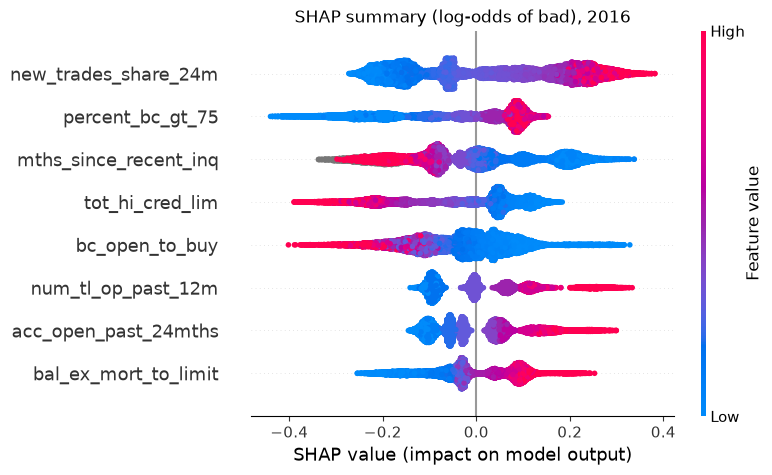

In [5]:
# Evidence — SHAP summary: which attributes drive the challenger, and in which direction
sv, bias = C.shap_values(booster, oot, max_rows=20000)
imp = C.shap_importance(sv); display(imp.head(15))
TOP = imp.attribute.head(8).tolist()
Xs = oot.loc[sv.index, g_attrs]
shap.summary_plot(sv[TOP].to_numpy(), Xs[TOP], show=False, max_display=len(TOP)); plt.title("SHAP summary (log-odds of bad), 2016"); plt.show()

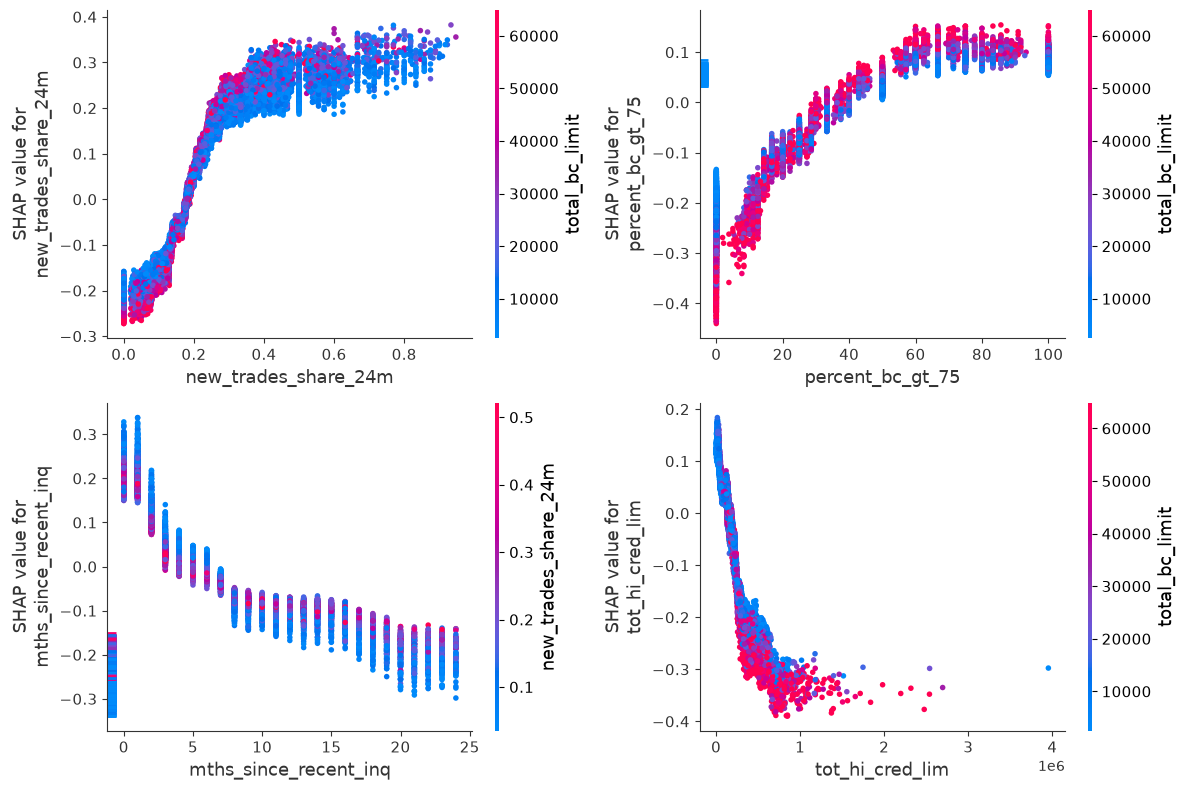

In [6]:
# Evidence — SHAP dependence for the top 4, coloured by the attribute each interacts with most
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for a, ax in zip(TOP[:4], axes.ravel()):
    shap.dependence_plot(a, sv.to_numpy(), Xs, interaction_index="auto", ax=ax, show=False)
plt.tight_layout(); plt.show()

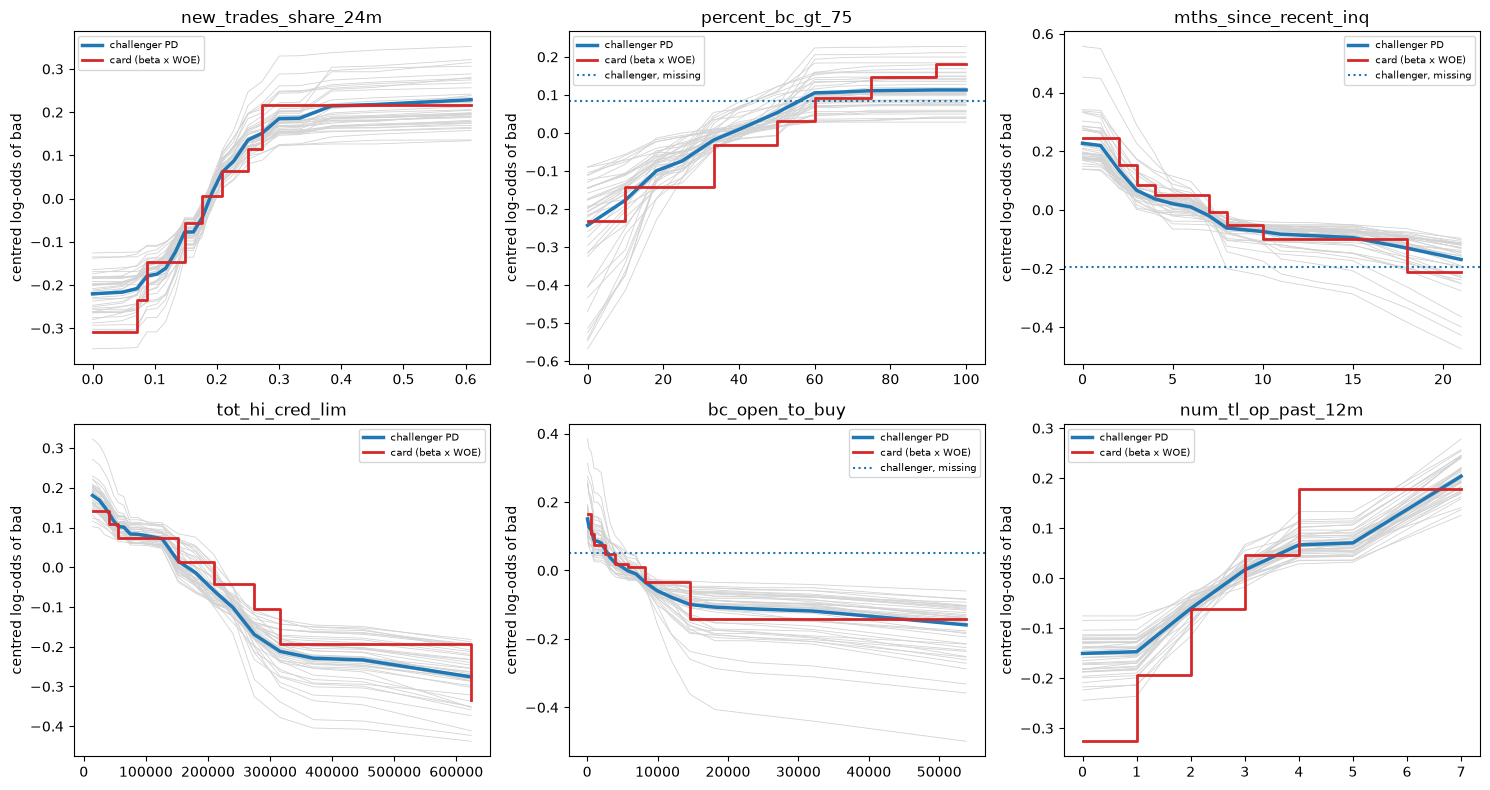

In [7]:
# Evidence — partial dependence (with ICE) against the card's own shape for the same attribute
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, ax in zip(TOP[:6], axes.ravel()):
    pdt, ice = E.partial_dependence(booster, oot, a, n_grid=20, max_rows=3000, ice=40)
    num = pdt[~pdt.is_missing]
    ax.plot(ice.index[:len(num)], ice.iloc[:len(num)] - ice.iloc[:len(num)].mean(), c="lightgrey", lw=0.6)
    ax.plot(num.value, num.mean_logit - num.mean_logit.mean(), c="C0", lw=2.5, label="challenger PD")
    if a in card_attrs:
        w = B.transform_woe(pd.DataFrame({a: num.value.to_numpy()}), {a: specs[a]})[a + "_woe"] * card.coef[a]
        ax.step(num.value, w - w.mean(), where="post", c="C3", lw=2, label="card (beta x WOE)")
    if pdt.is_missing.any():
        ax.axhline(pdt.mean_logit.iloc[-1] - num.mean_logit.mean(), ls=":", c="C0", label="challenger, missing")
    ax.set_title(a); ax.set_ylabel("centred log-odds of bad"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [8]:
# Evidence — interaction strength: exact pairwise SHAP interactions, then Friedman's H on the top pairs
pairs = E.shap_interaction_pairs(booster, oot, top=15, max_rows=5000); display(pairs)
H = E.friedman_h_pairs(booster, oot, list(zip(pairs.a, pairs.b))[:8], n_rows=300); display(H)
inter = C.interaction_strength(booster, g_attrs, oot, max_rows=3000)
print("share of SHAP variance that is interaction, mean over attributes: %.3f" % inter.interaction_share.mean())
pairs.merge(H, on=["a", "b"], how="left").to_csv(config.DOCS_DIR / "exhibits" / "interaction_pairs.csv", index=False)

,a,b,mean_abs_interaction,main_a,main_b,share_of_interaction
0,tot_cur_bal,tot_hi_cred_lim,0.02915,0.02389,0.11460,0.04211
1,bc_open_to_buy,new_trades_share_24m,0.01857,0.08226,0.16223,0.02682
2,percent_bc_gt_75,bc_open_to_buy,0.01646,0.11684,0.08226,0.02378
3,percent_bc_gt_75,total_bc_limit,0.01594,0.11684,0.03473,0.02302
4,new_trades_share_24m,bal_ex_mort_to_limit,0.01554,0.16223,0.07888,0.02244
5,mths_since_recent_inq,new_trades_share_24m,0.01336,0.11015,0.16223,0.01930
6,mths_since_recent_inq,mo_sin_rcnt_tl,0.01299,0.11015,0.04786,0.01877
7,mths_since_recent_inq,percent_bc_gt_75,0.01206,0.11015,0.11684,0.01742
8,inq_last_6mths,mths_since_recent_inq,0.00932,0.05114,0.11015,0.01347
9,revol_bal,tot_cur_bal,0.00932,0.05636,0.02389,0.01346


,a,b,h2
0,percent_bc_gt_75,total_bc_limit,0.0263
1,mths_since_recent_inq,mo_sin_rcnt_tl,0.0138
2,bc_open_to_buy,new_trades_share_24m,0.0129
3,tot_cur_bal,tot_hi_cred_lim,0.0100
4,percent_bc_gt_75,bc_open_to_buy,0.0093
5,new_trades_share_24m,bal_ex_mort_to_limit,0.0083
6,mths_since_recent_inq,percent_bc_gt_75,0.0054
7,mths_since_recent_inq,new_trades_share_24m,0.0046


share of SHAP variance that is interaction, mean over attributes: 0.121


### Decision Y — Interactions to carry back

A pair is worth carrying back when it is strong on both measures (SHAP interaction mass and H²), the crossed attribute has a story you can tell a consumer ("high utilisation *and* a recent inquiry"), and it is stable across vintages. Each candidate below is crossed at the GBM's own best split thresholds, binned like any categorical attribute, and offered to the stepwise selection with the card's attributes; the Gini gain is the paired DeLong difference on 2016. Pick the pairs to keep (edit `CARRY_BACK`).

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Carry back no interaction. None of the three crosses entered the card.**

- **They are not strong on both measures.**
  - The largest SHAP interaction pair, `tot_cur_bal × tot_hi_cred_lim` (mean |interaction| 0.0292), has H² of only 0.0100.
  - The highest H², `percent_bc_gt_75 × total_bc_limit`, is 0.0263.
  - Interaction is 12.1% of SHAP variance on average across attributes.
- **None entered the stepwise.** The three crosses were offered alone and together. None did, so the 2016 Gini stays 0.2838 (IVs 0.0402, 0.1055 and 0.0397). The card's existing attributes already carry what the crosses add.
- **The strongest pair is not a consumer story anyway.** `tot_cur_bal × tot_hi_cred_lim` is cut at 224,366 and 224,087, which amounts to a near-duplicate pair of balance fields rather than a consumer story.
- **Story-bearing pairs:** `bc_open_to_buy × new_trades_share_24m` and `mths_since_recent_inq × percent_bc_gt_75` are the two with a plausible consumer story. Revisit them only if the card is re-developed.

In [9]:
CARRY_BACK = list(zip(pairs.a, pairs.b))[:3]          # edit
rows, extra = [], {}
tr_x, oot_x = tr.copy(), oot.copy()
for a, b in CARRY_BACK:
    ta, tb = E.top_threshold(booster, a), E.top_threshold(booster, b)
    col = f"{a}_x_{b}"
    tr_x[col] = E.cross_attribute(tr, a, b, ta, tb); oot_x[col] = E.cross_attribute(oot, a, b, ta, tb)
    spec = B.fit_categorical(tr_x[col], tr_x["bad"], name=col)
    r = E.refit_card_with(tr_x, oot_x, card, specs, {col: spec})
    rows.append({"pair": col, "thresholds": (round(ta, 3), round(tb, 3)), "iv": round(spec.iv, 4), "entered": bool(r["entered"]),
                 "gini_before": round(r["gini_before"], 4), "gini_after": round(r["gini_after"], 4),
                 "gini_gain": round(r["gini_gain"], 4), "p_value": round(r["p_value"], 4)})
    extra[col] = spec
carry = pd.DataFrame(rows); display(carry)
joint = E.refit_card_with(tr_x, oot_x, card, specs, extra)
print(f"all {len(extra)} crosses offered together: entered {joint['entered']} · Gini {joint['gini_before']:.4f} -> {joint['gini_after']:.4f} (p = {joint['p_value']:.3g})")
carry.to_csv(config.DOCS_DIR / "exhibits" / "interaction_carry_back.csv", index=False)

,pair,thresholds,iv,entered,gini_before,gini_after,gini_gain,p_value
0,tot_cur_bal_x_tot_hi_cred_lim,"(224366.0, 224087.0)",0.0402,False,0.2838,0.2838,0.0,NaN
1,bc_open_to_buy_x_new_trades_share_24m,"(2680.0, 0.177)",0.1055,False,0.2838,0.2838,0.0,NaN
2,percent_bc_gt_75_x_bc_open_to_buy,"(30.0, 2680.0)",0.0397,False,0.2838,0.2838,0.0,NaN


all 3 crosses offered together: entered [] · Gini 0.2838 -> 0.2838 (p = nan)


In [10]:
# Evidence — reason-code agreement for the applicants the card would decline at the pilot approval rate
sc = S.score(oot, card, specs)["score"]
declined = oot[sc < sc.quantile(1 - config.APPROVAL_RATE_FOR_SWAP)]
sample = declined.sample(min(3000, len(declined)), random_state=42)
rc_card = S.reason_codes(sample, card, specs, meanings=MEANINGS, missing_reasons=A.MISSING_REASONS)
sv_d, _ = C.shap_values(booster, sample, max_rows=len(sample))
rc_gbm = C.gbm_reason_codes(sv_d.loc[sample.index], meanings=MEANINGS)
# Like for like: a GBM restricted to the card's attributes, with the tuned settings
tuning = json.loads((MODELS / "challenger_tuning.json").read_text(encoding="utf-8"))
g_card = C.fit_xgb(tr, tr["bad"], va, va["bad"], card_attrs, monotone=True, params=tuning["xgb_params"])
rc_gbm_card = C.gbm_reason_codes(C.shap_values(g_card, sample, max_rows=len(sample))[0].loc[sample.index], meanings=MEANINGS)
agree = pd.DataFrame({"GBM, all candidates": E.reason_code_agreement(rc_card, rc_gbm)[0],
                      "GBM, card attributes only": E.reason_code_agreement(rc_card, rc_gbm_card)[0]})
display(agree.round(3))
display(E.first_reason_crosstab(rc_card, rc_gbm_card))
agree.to_csv(config.DOCS_DIR / "exhibits" / "reason_code_agreement.csv")

,"GBM, all candidates","GBM, card attributes only"
n,3000.000,3000.000
mean_overlap,2.462,3.091
share_same_first_reason,0.577,0.611
share_no_reason_in_common,0.004,0.000
share_full_agreement,0.047,0.250
mean_rank_gap_shared,0.752,0.734


reason_1,Months since the most recent inquiry,Percent of bankcards above 75% utilised,Total high credit / limit,Trades opened in 24 months as a share of all trades,Trades opened in the last 12 months,other
reason_1,,,,,,
Months since the most recent inquiry,532,12,0,297,134,77
No active bankcard on file,6,1,0,20,4,9
Percent of bankcards above 75% utilised,0,30,0,2,4,62
Total high credit / limit,0,44,1,88,27,116
Trades opened in 24 months as a share of all trades,0,0,0,1066,212,42
Trades opened in the last 12 months,0,0,0,2,204,8


### Decision Z — Reason-code position

The card's reasons are points lost against each attribute's best bin; the GBM's are the largest positive SHAP contributions against the *average* applicant. These are different reference points, so some disagreement is by construction. Is the agreement on the first reason high enough that a consumer would hear the same story? Where they disagree, which is right (look at a few rows)? If the GBM were promoted, would its reasons pass an adverse-action review?

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**The first reason agrees often enough for a pilot, but not for promotion of the GBM without its own reason-code review.**

These are the 3,000 applicants the card declines at the pilot approval rate.

| | GBM, all candidates | GBM, card attributes only |
|---|---:|---:|
| Same first reason as the card | 57.7% | 61.1% |
| Mean shared top-4 reasons | 2.46 | 3.09 |
| Full agreement on all four | 4.7% | 25.0% |
| No reason in common | 0.4% | 0.0% |

**Where they disagree, the pattern is systematic, not random.** The first-reason crosstab compares the card (rows) with the GBM on the card's own attributes (columns):
- The card leads with the share of trades opened in 24 months for 1,320 applicants; the GBM agrees on 1,066 and leads with trades opened in 12 months on 212.
- The card leads with months since the most recent inquiry for 1,052; the GBM agrees on only 532 and leads with the share of new trades on 297.
- The reference points differ: the card measures points lost against the best bin ("never inquired" is the safest bin), the GBM measures SHAP against the average applicant. So a recent inquiry comes first more often for the card than for the GBM. Neither is wrong.

**"No active bankcard on file" is the card's first reason for 40 applicants.** The GBM has no matching reason text; for 20 of them it leads with the share of new trades.

**Adverse-action review:** the GBM's reasons are monotone in each attribute, so they would pass a direction check. But the 42% first-reason disagreement means the notices would change for many declined applicants if the GBM were promoted.